# Chương 2 bài 2a Trực quan hóa tiểu đường

**Nguồn:** Lab EDA, bài tập thực hành 2 phần 1.2, trang 8

**Đề bài:** Thực hiện trực quan hóa dữ liệu bệnh tiểu đường.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C2_BT02a_TrucQuan_TieuDuong'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Kiểm tra dữ liệu và số 0

In [2]:
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
           'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
raw = pd.read_csv(DATA / 'pima-indians-diabetes.csv', header=None, names=columns)
invalid_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = raw[invalid_zero].eq(0).sum()
df = raw.copy()
df[invalid_zero] = df[invalid_zero].replace(0, np.nan)
print('Raw shape:', raw.shape)
print('Zero placeholders:\n', zero_counts)
print('Class distribution:\n', df['Outcome'].value_counts())

Raw shape: (768, 9)
Zero placeholders:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Class distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64


## 2 Trực quan hóa đơn biến và hai biến

Outcome                     1.000000
Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64


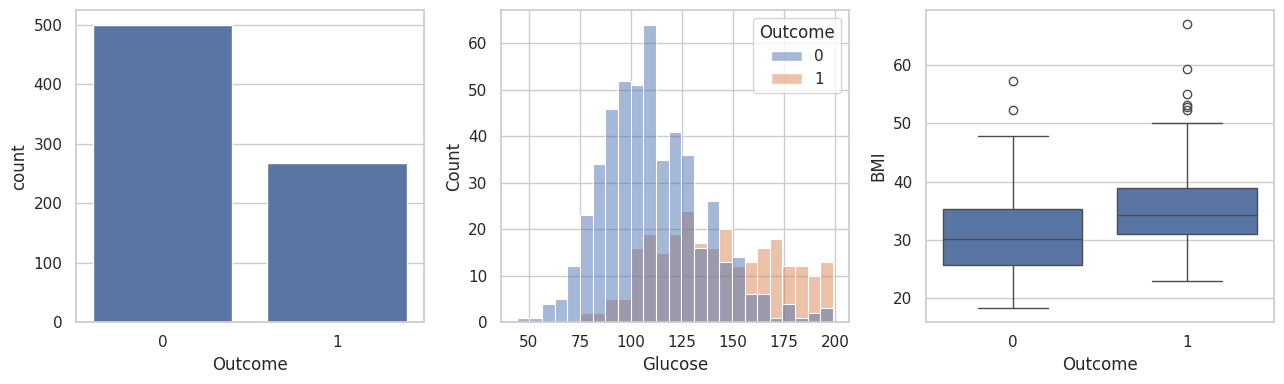

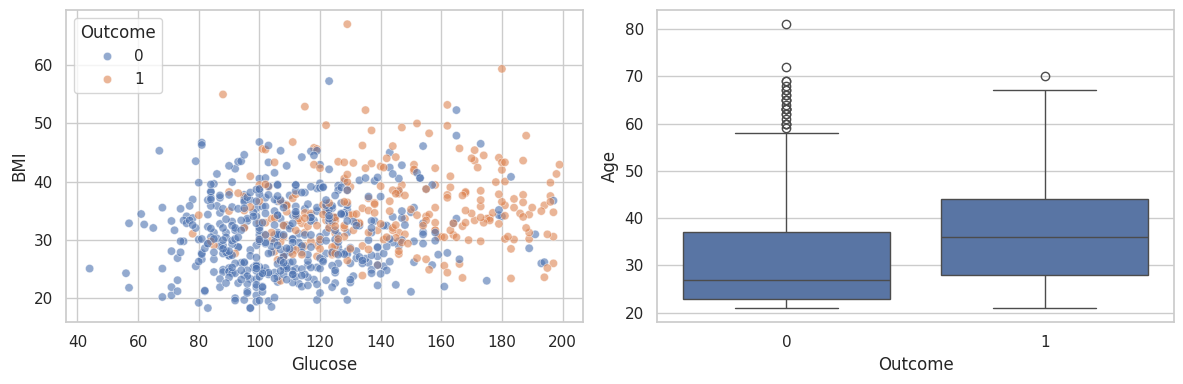

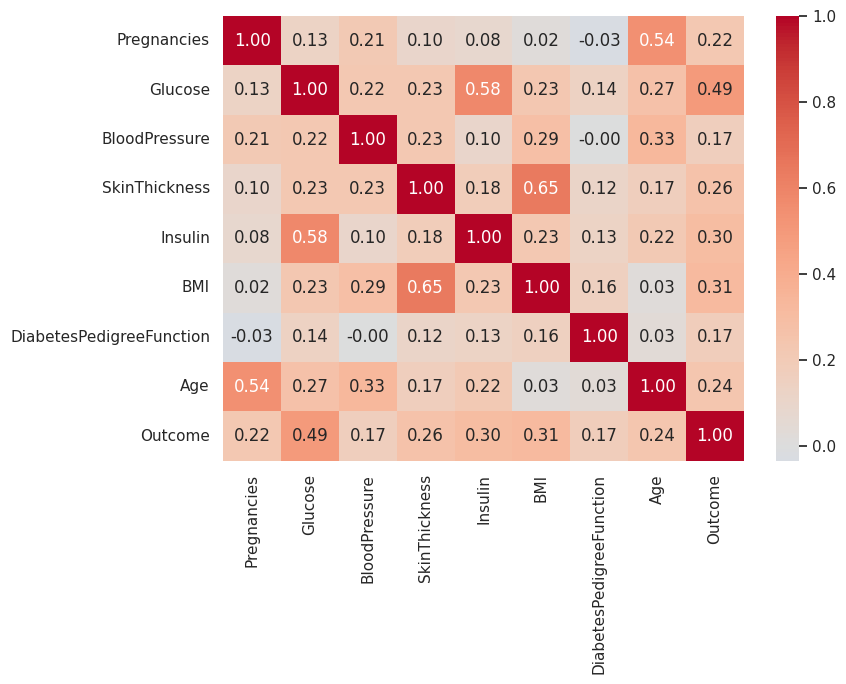

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sns.countplot(data=df, x='Outcome', ax=axes[0])
sns.histplot(data=df, x='Glucose', hue='Outcome', bins=25, ax=axes[1])
sns.boxplot(data=df, x='Outcome', y='BMI', ax=axes[2])
save_fig('01_phan_bo_va_nhom.png')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x='Glucose', y='BMI', hue='Outcome', alpha=0.6, ax=axes[0])
sns.boxplot(data=df, x='Outcome', y='Age', ax=axes[1])
save_fig('02_hai_bien.png')
plt.figure(figsize=(9, 7))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
save_fig('03_tuong_quan.png')
print(corr['Outcome'].sort_values(ascending=False))
save_summary({'rows':len(df), 'corr_glucose_outcome':float(corr.loc['Glucose','Outcome']),
              'corr_bmi_outcome':float(corr.loc['BMI','Outcome']),
              'class_1_fraction':float(df.Outcome.mean())})

## Nhận xét và giới hạn
Các nhóm Outcome có thể chồng lấn ở Glucose và BMI, nên không dùng một ngưỡng đơn giản để kết luận cho cá nhân. Giá trị thiếu không được điền trước khi vẽ phân bố. Tương quan được tính trên các cặp quan sát đủ dữ liệu.